# PowerPulse: Hourly-Data Electricity Forecasting for Indian Homes

**Input:** the UCI household power dataset, already aggregated from minutes to **hourly** values.
**Output:** a daily plan (next 7 days), next-week total and next-month (30-day) total, in kWh and estimated ₹,
for an Indian household using only its **electricity bill**.

## How the model is made to work for Indian homes
The training data is one French home (~26 kWh/day, electric heating, winter peak). A typical Indian bill is
3-10 kWh/day with a summer (cooling) peak. Training on raw kWh would copy the French size and seasons. So:

1. **Scale-free target.** The model predicts consumption *relative to the house's own recent 28-day level*,
   not raw kWh. Any household size works; the bill provides the level.
2. **Seasonality removed from training, put back from the user's region.** The French seasonal curve is divided
   out before training. At forecast time the Indian household's own curve is used: how its bills respond to
   local temperature (Open-Meteo), or a monthly curve from 12+ months of bills.
3. **All past bills are used.** A bill-history model reads up to the last 6 bills (level, trend, swings).
4. **Indian calendar.** Holidays come from the `holidays` package for India and the chosen state (default Telangana).
5. **Indian bill.** Billing days, units and charges come from the bill JSON; slab tariff and Gruha Jyothi
   (free up to 200 units/month) are applied to the forecast.

What still comes from the French home: weekday/holiday effects and how consumption drifts around its recent
level. That transfers reasonably well; seasonality does not, which is why it is supplied separately.

# Section 1: Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install pandas numpy xgboost scikit-learn matplotlib holidays -q

In [ ]:
import json
import os
import warnings

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 6)

# ---------- training data: UCI household, hourly ----------
HOURLY_PATH = '/content/drive/MyDrive/powerpulse/hourly_power_consumption_cleaned.csv'
DATETIME_COL = None      # None = auto-detect ('Datetime', 'timestamp', or 'Date' + 'Time')
VALUE_COL = None         # None = auto-detect ('Global_active_power', or a kWh/consumption column)
VALUE_UNIT = 'auto'      # 'auto' | 'kWh' (= mean kW per hour) | 'kW_minute_sum' (sum of 60 minute readings) | 'Wh'
DAYFIRST = True          # UCI dates are DD/MM/YYYY
TRAIN_COUNTRY = 'FR'     # holidays of the training household's country
MIN_HOURS_PER_DAY = 20   # fewer valid hours than this = meter outage day

TRAIN_END = '2009-09-18'
VAL_END = '2010-04-22'
TEST_START, TEST_END = '2010-04-23', '2010-11-25'

# ---------- Indian household ----------
# Every bill uploaded for this home (JSON from the bill reader). Order doesn't matter; the last 6 are used.
BILL_JSON_PATHS = ['/content/drive/MyDrive/powerpulse/powerpulse_electricity_bill.json']
# Older bills typed in by hand (meter-reading dates, DD/MM/YYYY):
BILL_HISTORY = [
    # {'from': '04/07/2026', 'to': '04/08/2026', 'units': 102},
]
TARGET_COUNTRY, TARGET_STATE = 'IN', 'TS'   # TS = Telangana; e.g. 'KA', 'MH', 'TN', 'AP', 'DL'
# Home location, used to download daily temperatures (Open-Meteo, free). None, None = no weather.
LATITUDE, LONGITUDE = 17.385, 78.487        # Hyderabad; set to the household's town
CDD_BASE_C = 24.0                           # cooling degree-days count temperature above this

OUTPUT_DIR = '.'

# Section 2: Load the hourly file
Hourly files made with `resample('h').sum()` turn meter outages into **0 kWh hours**, and that is what broke
v1. Hours under 0.01 kWh are treated as missing: a real home always has some standby load (fridge, router).

In [ ]:
def detect_columns(frame):
    lower = {c.lower().strip(): c for c in frame.columns}
    if DATETIME_COL:
        ts = frame[DATETIME_COL].astype(str)
    elif 'date' in lower and 'time' in lower:
        ts = frame[lower['date']].astype(str) + ' ' + frame[lower['time']].astype(str)
    else:
        cand = [c for c in frame.columns if any(k in c.lower() for k in ('datetime', 'timestamp', 'date', 'time'))]
        ts = frame[cand[0] if cand else frame.columns[0]].astype(str)
    ts = pd.to_datetime(ts, dayfirst=DAYFIRST)

    if VALUE_COL:
        vcol = VALUE_COL
    elif 'global_active_power' in lower:
        vcol = lower['global_active_power']
    else:
        vcol = next(c for c in frame.columns
                    if any(k in c.lower() for k in ('kwh', 'consumption', 'energy', 'active_power', 'power', 'load')))
    return ts, vcol


def to_kwh(values):
    unit = VALUE_UNIT
    if unit == 'auto':
        med = values[values > 0].median()
        unit = 'kWh' if med < 10 else ('kW_minute_sum' if med < 200 else 'Wh')
    factor = {'kWh': 1.0, 'kW_minute_sum': 1 / 60, 'Wh': 1 / 1000}[unit]
    return values * factor, unit


hourly_raw = pd.read_csv(HOURLY_PATH, sep=None, engine='python', na_values=['?', ''])
ts, vcol = detect_columns(hourly_raw)
kwh, unit = to_kwh(pd.to_numeric(hourly_raw[vcol], errors='coerce'))
hourly = kwh.groupby(ts.dt.floor('h').values).mean()
hourly = hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq='h'))
zero_hours = int((hourly < 0.01).sum())
hourly[hourly < 0.01] = np.nan

print(f'Value column: {vcol!r}, detected unit: {unit} -> converted to kWh per hour')
print(f'Hours: {len(hourly)}  ({hourly.index.min()} to {hourly.index.max()})')
print(f'Missing hours: {int(hourly.isna().sum())} (of which {zero_hours} were zero-filled gaps)')
print(hourly.describe())

Value column: 'Global_active_power', detected unit: kWh -> converted to kWh per hour
Hours: 34589  (2006-12-16 17:00:00 to 2010-11-26 21:00:00)
Missing hours: 0 (of which 0 were zero-filled gaps)
count    34589.000000
mean         1.089029
std          0.895663
min          0.124000
25%          0.342233
50%          0.804933
75%          1.575300
max          6.560533
Name: Global_active_power, dtype: float64


# Section 3: Hourly -> daily, with outage handling and intraday shape
Daily kWh = mean of the valid hours x 24. Days with fewer than `MIN_HOURS_PER_DAY` valid hours are outages:
they are imputed so lag features keep working, but get zero training weight and are excluded from evaluation.
The hourly data also gives each day's **shape** (night base load, evening share, peak), used as features.

In [ ]:
hdf = pd.DataFrame({'kWh': hourly})
hdf['Date'] = hdf.index.normalize()
hdf['Hour'] = hdf.index.hour
grp = hdf.groupby('Date')['kWh']
daily = pd.DataFrame({'Hours_valid': grp.count(), 'Mean_kWh_per_h': grp.mean()})
daily['Night_ratio'] = hdf[hdf['Hour'] < 6].groupby('Date')['kWh'].mean() / daily['Mean_kWh_per_h']
daily['Evening_ratio'] = hdf[hdf['Hour'] >= 18].groupby('Date')['kWh'].mean() / daily['Mean_kWh_per_h']
daily['Peak_ratio'] = grp.max() / daily['Mean_kWh_per_h']
daily = daily.reset_index()

# drop partial first/last days of the file
while daily['Hours_valid'].iloc[0] < 24:
    daily = daily.iloc[1:]
while daily['Hours_valid'].iloc[-1] < 24:
    daily = daily.iloc[:-1]
daily = daily.reset_index(drop=True)

daily['Is_Outage'] = daily['Hours_valid'] < MIN_HOURS_PER_DAY
daily['Daily_kWh'] = np.where(daily['Is_Outage'], np.nan, daily['Mean_kWh_per_h'] * 24)
daily.loc[daily['Is_Outage'], ['Night_ratio', 'Evening_ratio', 'Peak_ratio']] = np.nan
s = daily.set_index('Date')['Daily_kWh']
seasonal_fill = pd.concat([s.shift(k) for k in (7, -7, 14, -14)], axis=1).mean(axis=1)
daily['Daily_kWh'] = s.fillna(seasonal_fill).interpolate().values

print(f"Days: {len(daily)}  ({daily['Date'].min().date()} to {daily['Date'].max().date()})")
print(f"Outage days: {daily['Is_Outage'].sum()}")
print(daily.loc[daily['Is_Outage'], ['Date', 'Hours_valid']].to_string(index=False))
print(daily['Daily_kWh'].describe())

Days: 1440  (2006-12-17 to 2010-11-25)
Outage days: 0
Empty DataFrame
Columns: [Date, Hours_valid]
Index: []
count    1440.000000
mean       26.125620
std        10.098798
min         4.171633
25%        19.487717
50%        25.733800
75%        31.570108
max        79.556433
Name: Daily_kWh, dtype: float64


# Section 4: Seasonal curves
A smooth seasonal index (mean = 1.0) from monthly averages. The training household's curve is estimated on the
training period only. The Indian household's curve is built from its bills and local weather in Section 12.

In [ ]:
MID_DOY = np.array([15, 46, 74, 105, 135, 166, 196, 227, 258, 288, 319, 349])


def make_seasonal_curve(month_index):
    vals = np.array([month_index[m] for m in range(1, 13)], dtype=float)
    vals = vals / vals.mean()
    x = np.concatenate([MID_DOY - 365, MID_DOY, MID_DOY + 365])
    y = np.tile(vals, 3)
    return lambda dates: np.interp(pd.DatetimeIndex(dates).dayofyear, x, y)


def month_index_from_history(month_totals):
    """month_totals: {month_number: average kWh/day}. Missing months are interpolated around the year."""
    if len(month_totals) < 3:
        return None
    known = pd.Series(month_totals, dtype=float).sort_index()
    ext = pd.concat([known.set_axis(known.index - 12), known, known.set_axis(known.index + 12)])
    full = ext.reindex(range(-11, 25)).interpolate().loc[1:12]
    return full.to_dict()


real_train = daily[(daily['Date'] <= TRAIN_END) & ~daily['Is_Outage']]
train_month_index = real_train.groupby(real_train['Date'].dt.month)['Daily_kWh'].mean().to_dict()
season_train = make_seasonal_curve(train_month_index)
daily['Season'] = season_train(daily['Date'])
daily['kWh_deseason'] = daily['Daily_kWh'] / daily['Season']

print('Training household monthly index:')
print({m: round(v / np.mean(list(train_month_index.values())), 2) for m, v in train_month_index.items()})

Training household monthly index:
{1: np.float64(1.34), 2: np.float64(1.16), 3: np.float64(1.15), 4: np.float64(0.96), 5: np.float64(0.92), 6: np.float64(0.8), 7: np.float64(0.63), 8: np.float64(0.52), 9: np.float64(0.88), 10: np.float64(1.02), 11: np.float64(1.22), 12: np.float64(1.4)}


# Section 5: Scale-free features (no leakage)
Everything is divided by **L = the 28-day mean up to yesterday** (deseasonalised), so a 3 kWh/day home and a
26 kWh/day home look alike to the model. Every feature for day *t* uses data up to *t-1* only.

In [ ]:
LAGS = [1, 2, 3, 4, 5, 6, 7, 14, 21, 28]
CALENDAR_COLS = ['DayOfWeek', 'IsWeekend', 'IsHoliday']
# how much the seasonal curve rises/falls ahead vs the last 28 days (works with any region's curve)
SEASON_COLS = ['Season_shift_1d', 'Season_shift_7d', 'Season_shift_30d']
HISTORY_COLS = ([f'Lag_{k}d_rel' for k in LAGS]
                + ['RollMean_3d_rel', 'RollMean_7d_rel', 'RollMean_14d_rel', 'RollStd_7d_rel',
                   'RollMin_7d_rel', 'RollMax_7d_rel', 'EWM_7_rel', 'SameDOW_4w_rel', 'Level_vs_year',
                   'Night_ratio_1d', 'Evening_ratio_1d', 'Peak_ratio_1d',
                   'Night_ratio_7d', 'Evening_ratio_7d', 'Peak_ratio_7d', 'Outage_last7'])
FEATURE_COLS = CALENDAR_COLS + SEASON_COLS + HISTORY_COLS
OPTIONAL_COLS = ['Level_vs_year'] + [c for c in HISTORY_COLS if 'ratio' in c]
REQUIRED_COLS = [c for c in FEATURE_COLS if c not in OPTIONAL_COLS]


def holiday_calendar(country, subdiv=None):
    return holidays.country_holidays(country, subdiv=subdiv, years=range(2005, 2036))


def calendar_features(data, hol):
    data['DayOfWeek'] = data['Date'].dt.dayofweek
    data['IsWeekend'] = (data['DayOfWeek'] >= 5).astype(int)
    data['IsHoliday'] = data['Date'].dt.date.map(lambda x: x in hol).astype(int)
    return data


def season_window(season_fn, dates, offsets):
    return sum(season_fn(dates + pd.Timedelta(days=k)) for k in offsets)


def build_features(data, hol, season_fn):
    data = calendar_features(data.copy(), hol)
    y = data['kWh_deseason']
    past = y.shift(1)
    L = past.rolling(28).mean()
    data['Level'] = L
    for k in LAGS:
        data[f'Lag_{k}d_rel'] = y.shift(k) / L
    for w in (3, 7, 14):
        data[f'RollMean_{w}d_rel'] = past.rolling(w).mean() / L
    data['RollStd_7d_rel'] = past.rolling(7).std() / L
    data['RollMin_7d_rel'] = past.rolling(7).min() / L
    data['RollMax_7d_rel'] = past.rolling(7).max() / L
    data['EWM_7_rel'] = past.ewm(span=7).mean() / L
    data['SameDOW_4w_rel'] = (y.shift(7) + y.shift(14) + y.shift(21) + y.shift(28)) / 4 / L
    data['Level_vs_year'] = L / past.rolling(365, min_periods=120).mean()
    for c in ('Night_ratio', 'Evening_ratio', 'Peak_ratio'):
        data[f'{c}_1d'] = data[c].shift(1)
        data[f'{c}_7d'] = data[c].shift(1).rolling(7, min_periods=4).mean()
    data['Outage_last7'] = data['Is_Outage'].astype(float).shift(1).rolling(7).sum()
    # the seasonal curve is a known function of the date, so future values are available
    season_past = season_window(season_fn, data['Date'], range(-28, 0)) / 28
    data['Season_shift_1d'] = data['Season'] / season_past

    # targets, relative to L: today, and the mean of the next 7 / 30 days
    data['Target_1d'] = y / L
    for h in (7, 30):
        data[f'Target_{h}d'] = sum(y.shift(-k) for k in range(h)) / h / L
        data[f'Season_sum_{h}d'] = season_window(season_fn, data['Date'], range(h))
        data[f'Season_shift_{h}d'] = data[f'Season_sum_{h}d'] / h / season_past
        data[f'Actual_{h}d_kWh'] = sum(data['Daily_kWh'].shift(-k) for k in range(h))
        data[f'Outages_next_{h}d'] = sum(data['Is_Outage'].astype(int).shift(-k) for k in range(h))
    # weight so that the loss is in kWh, and outage days don't count
    data['Weight'] = np.where(data['Is_Outage'], 0.0, data['Level'] * data['Season'])
    return data


train_hol = holiday_calendar(TRAIN_COUNTRY)
feat = build_features(daily, train_hol, season_train).dropna(subset=REQUIRED_COLS).reset_index(drop=True)
print(f'{len(FEATURE_COLS)} features, {len(feat)} usable days')

32 features, 1412 usable days


# Section 6: Chronological split

In [ ]:
def split(data, horizon=1):
    gap = pd.Timedelta(days=horizon - 1)
    tr = data[data['Date'] <= pd.Timestamp(TRAIN_END) - gap]
    va = data[(data['Date'] > TRAIN_END) & (data['Date'] <= pd.Timestamp(VAL_END) - gap)]
    te = data[(data['Date'] >= TEST_START) & (data['Date'] <= pd.Timestamp(TEST_END) - gap)]
    return tr, va, te


train, val, test = split(feat)
test_real = test[~test['Is_Outage']]
for name, part in [('Train', train), ('Validation', val), ('Test', test)]:
    print(f"{name:<11} {len(part):4d} days  {part['Date'].min().date()} to {part['Date'].max().date()}")
print(f'Test days used for evaluation (outages removed): {len(test_real)}')

Train        979 days  2007-01-14 to 2009-09-18
Validation   216 days  2009-09-19 to 2010-04-22
Test         217 days  2010-04-23 to 2010-11-25
Test days used for evaluation (outages removed): 217


# Section 7: Train the daily, weekly and monthly models

In [ ]:
PARAMS = {
    'objective': 'reg:absoluteerror',
    'eval_metric': 'mae',
    'max_depth': 3,
    'learning_rate': 0.02,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'min_child_weight': 10,
    'reg_lambda': 5.0,
    'random_state': 42,
}


def train_model(tr, va, target):
    dtr = xgb.DMatrix(tr[FEATURE_COLS], label=tr[target], weight=tr['Weight'])
    dva = xgb.DMatrix(va[FEATURE_COLS], label=va[target], weight=va['Weight'])
    return xgb.train(PARAMS, dtr, num_boost_round=3000, evals=[(dva, 'val')],
                     early_stopping_rounds=100, verbose_eval=False)


def predict_ratio(model, data):
    return model.predict(xgb.DMatrix(data[FEATURE_COLS]), iteration_range=(0, model.best_iteration + 1))


models, tests = {}, {}
for h in (1, 7, 30):
    target = f'Target_{h}d'
    data_h = feat.dropna(subset=[target])
    tr_h, va_h, te_h = split(data_h, horizon=h)
    te_h = te_h[~te_h['Is_Outage']] if h == 1 else te_h[te_h[f'Outages_next_{h}d'] <= h // 7]
    models[h] = train_model(tr_h, va_h, target)
    tests[h] = te_h
    print(f'{h:>2}-day model: best iteration {models[h].best_iteration}, {len(te_h)} test origins')

 1-day model: best iteration 363, 217 test origins
 7-day model: best iteration 386, 211 test origins
30-day model: best iteration 1262, 188 test origins


# Section 8: Evaluation in kWh (training household, test period)
kWh prediction = predicted ratio x L x seasonal index (summed over the window for weekly/monthly).

In [ ]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAPE': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
            'R2': r2_score(y_true, y_pred)}


def to_kwh_pred(ratio, data, h):
    season = data['Season'] if h == 1 else data[f'Season_sum_{h}d']
    return ratio * data['Level'] * season


results, preds = {}, {}
for h, label in [(1, 'Daily'), (7, 'Weekly (7 days)'), (30, 'Monthly (30 days)')]:
    te_h = tests[h]
    actual = te_h['Daily_kWh'] if h == 1 else te_h[f'Actual_{h}d_kWh']
    preds[h] = to_kwh_pred(predict_ratio(models[h], te_h), te_h, h)
    base = to_kwh_pred(te_h['RollMean_7d_rel'], te_h, h) if h < 30 else to_kwh_pred(1.0, te_h, h)
    results[f'{label} baseline'] = evaluate(actual, base)
    results[f'{label} XGBoost'] = evaluate(actual, preds[h])

summary = pd.DataFrame(results).T.round(3)
summary.columns = ['MAE (kWh)', 'RMSE (kWh)', 'MAPE (%)', 'R2']
print('Baselines: daily/weekly = last 7-day mean, monthly = last 28-day level, both with seasonal index')
print(summary.to_string())

Baselines: daily/weekly = last 7-day mean, monthly = last 28-day level, both with seasonal index
                            MAE (kWh)  RMSE (kWh)  MAPE (%)     R2
Daily baseline                  4.483       5.957    23.221  0.348
Daily XGBoost                   4.098       5.489    20.434  0.446
Weekly (7 days) baseline       22.016      29.052    15.233  0.452
Weekly (7 days) XGBoost        18.313      24.105    13.625  0.622
Monthly (30 days) baseline     79.394      98.552    12.977  0.491
Monthly (30 days) XGBoost      58.694      79.603     9.166  0.668


# Section 9: Visualisations

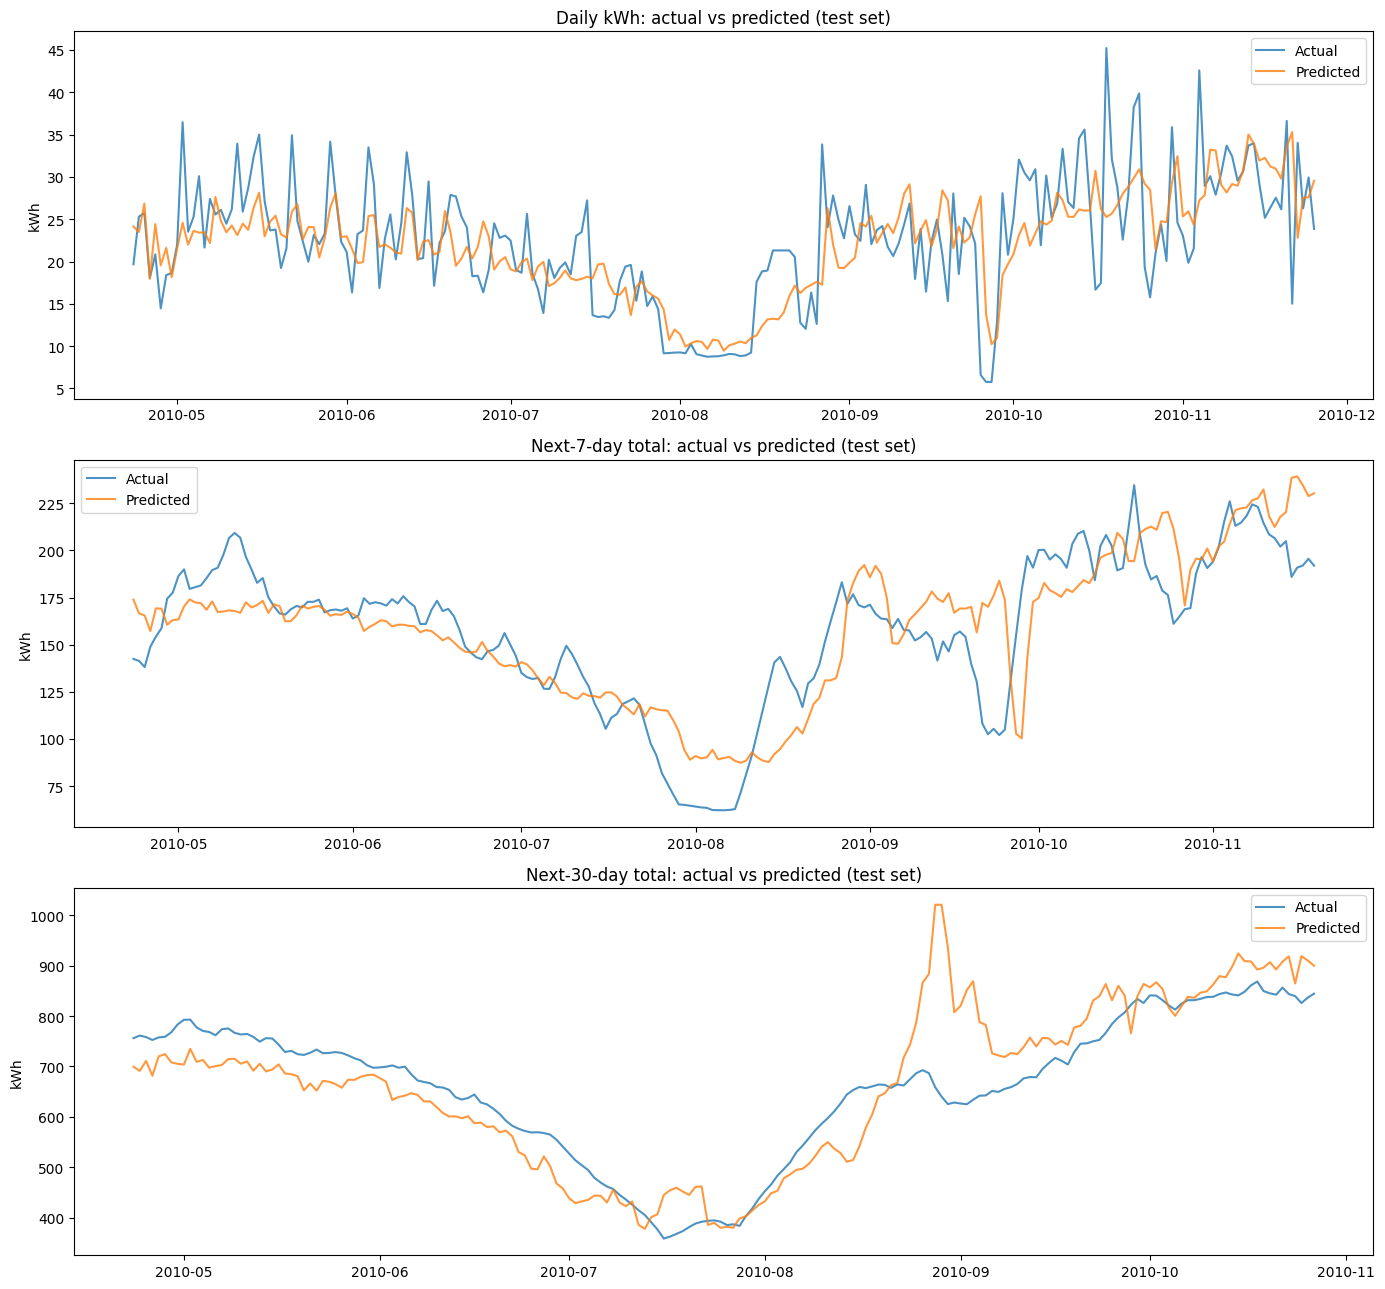

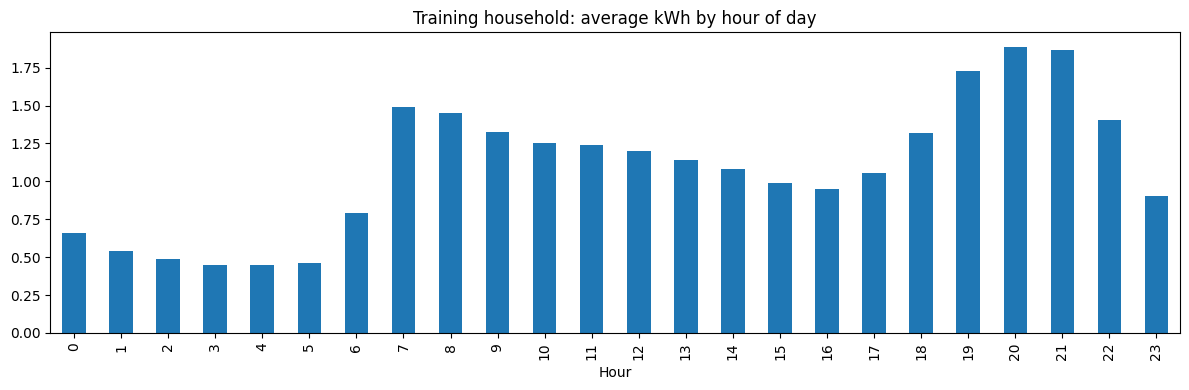

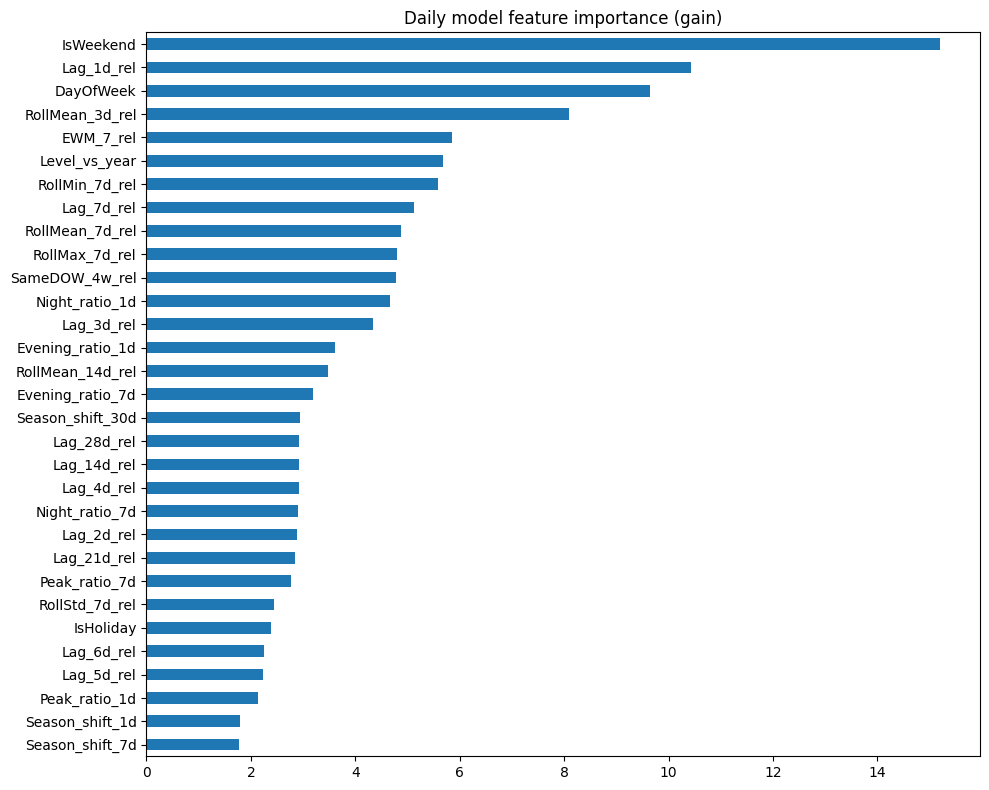

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13))
for ax, (h, title) in zip(axes, [(1, 'Daily kWh'), (7, 'Next-7-day total'), (30, 'Next-30-day total')]):
    te_h = tests[h]
    actual = te_h['Daily_kWh'] if h == 1 else te_h[f'Actual_{h}d_kWh']
    ax.plot(te_h['Date'], actual, label='Actual', alpha=0.8)
    ax.plot(te_h['Date'], preds[h], label='Predicted', alpha=0.8)
    ax.set_title(f'{title}: actual vs predicted (test set)')
    ax.set_ylabel('kWh')
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'actual_vs_predicted.png'))
plt.show()

profile = hdf.groupby('Hour')['kWh'].mean()
plt.figure(figsize=(12, 4))
profile.plot.bar()
plt.title('Training household: average kWh by hour of day')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hourly_profile.png'))
plt.show()

imp = pd.Series(models[1].get_score(importance_type='gain')).sort_values()
plt.figure(figsize=(10, 8))
imp.plot.barh()
plt.title('Daily model feature importance (gain)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'feature_importance.png'))
plt.show()

# Section 10: Refit on all data and save
Final models use all days with the iteration counts found above.

In [ ]:
final_models = {}
for h in (1, 7, 30):
    data_h = feat.dropna(subset=[f'Target_{h}d'])
    dall = xgb.DMatrix(data_h[FEATURE_COLS], label=data_h[f'Target_{h}d'], weight=data_h['Weight'])
    final_models[h] = xgb.train(PARAMS, dall, num_boost_round=models[h].best_iteration + 1)

# "typical history" used when only a bill is available (no daily readings for the Indian home)
real_feat = feat[~feat['Is_Outage']]
typical_history = real_feat[HISTORY_COLS].median().to_dict()
typical_history['Outage_last7'] = 0.0

for h, name in [(1, 'daily'), (7, 'weekly'), (30, 'monthly')]:
    final_models[h].save_model(os.path.join(OUTPUT_DIR, f'powerpulse_{name}_ratio_model.json'))
with open(os.path.join(OUTPUT_DIR, 'model_config.json'), 'w') as f:
    json.dump({'feature_cols': FEATURE_COLS, 'typical_history': typical_history,
               'target': 'consumption / trailing 28-day deseasonalised level'}, f, indent=2)
with open(os.path.join(OUTPUT_DIR, 'metrics.json'), 'w') as f:
    json.dump({k: {m: round(float(v), 4) for m, v in d.items()} for k, d in results.items()}, f, indent=2)
print('Saved 3 models, model_config.json and metrics.json')

Saved 3 models, model_config.json and metrics.json


In [ ]:
from google.colab import files
for name in ['powerpulse_daily_ratio_model.json', 'powerpulse_weekly_ratio_model.json',
             'powerpulse_monthly_ratio_model.json', 'model_config.json', 'metrics.json',
             'actual_vs_predicted.png', 'hourly_profile.png', 'feature_importance.png']:
    files.download(name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Section 11: Bill-history model (uses up to the last 6 bills)
A household's bills carry more than the latest level: they show the trend (rising or falling) and how much
usage swings. This model learns, from the training household cut into rolling 30-day "bills", how the last
**1-6 bills** predict the next 30 days. Bills are deseasonalised first, so the model learns trend and
persistence, not French seasons. It is trained with 1, 2, ... 6 bills available, so a new user with one bill still works.

In [ ]:
N_BILLS = 6
PERIOD_DAYS = 30
BILL_COLS = ['N_bills'] + [f'Bill_{k}_rel' for k in range(2, N_BILLS + 1)] + ['Season_shift_bill']


def bill_sequence_rows(data, season_fn):
    """One row per forecast start day: the previous 6 consecutive 30-day periods and the next 30 days."""
    y = data['kWh_deseason']
    m30 = y.rolling(PERIOD_DAYS).mean()
    out = pd.DataFrame({'Date': data['Date']})
    out['P1'] = m30.shift(1)                                 # most recent "bill", deseasonalised kWh/day
    for k in range(2, N_BILLS + 1):
        out[f'Bill_{k}_rel'] = m30.shift(PERIOD_DAYS * (k - 1) + 1) / out['P1']
    out['Season_sum_30d'] = season_window(season_fn, data['Date'], range(PERIOD_DAYS))
    out['Season_shift_bill'] = out['Season_sum_30d'] / season_window(season_fn, data['Date'], range(-PERIOD_DAYS, 0))
    out['Target'] = m30.shift(-(PERIOD_DAYS - 1)) / out['P1']
    out['Actual_30d_kWh'] = data['Daily_kWh'].rolling(PERIOD_DAYS).sum().shift(-(PERIOD_DAYS - 1))
    out['Last_bill_kWh'] = data['Daily_kWh'].rolling(PERIOD_DAYS).sum().shift(1)
    out['Outages_next_30d'] = data['Is_Outage'].astype(int).rolling(PERIOD_DAYS).sum().shift(-(PERIOD_DAYS - 1))
    out['Weight'] = out['P1'] * out['Season_sum_30d']
    return out


def with_n_bills(rows, n):
    rows = rows.copy()
    rows['N_bills'] = n
    for k in range(n + 1, N_BILLS + 1):
        rows[f'Bill_{k}_rel'] = np.nan
    return rows


seq = bill_sequence_rows(daily, season_train).dropna(subset=['P1', f'Bill_{N_BILLS}_rel', 'Target'])
seq_aug = pd.concat([with_n_bills(seq, n) for n in range(1, N_BILLS + 1)], ignore_index=True)
tr_s, va_s, te_s = split(seq_aug, horizon=PERIOD_DAYS)
te_s = te_s[te_s['Outages_next_30d'] <= 4]


def train_on(cols, tr, va, target='Target'):
    dtr = xgb.DMatrix(tr[cols], label=tr[target], weight=tr['Weight'])
    dva = xgb.DMatrix(va[cols], label=va[target], weight=va['Weight'])
    return xgb.train(PARAMS, dtr, num_boost_round=3000, evals=[(dva, 'val')],
                     early_stopping_rounds=100, verbose_eval=False)


bill_model = train_on(BILL_COLS, tr_s, va_s)
print(f'Bill-history model: best iteration {bill_model.best_iteration}\n')

bill_results = {}
one = te_s[te_s['N_bills'] == 1]
bill_results['Last bill repeated'] = evaluate(one['Actual_30d_kWh'], one['Last_bill_kWh'])
bill_results['Last bill + seasonal adjustment'] = evaluate(one['Actual_30d_kWh'], one['P1'] * one['Season_sum_30d'])
for n in (1, 3, 6):
    t = te_s[te_s['N_bills'] == n]
    ratio = bill_model.predict(xgb.DMatrix(t[BILL_COLS]), iteration_range=(0, bill_model.best_iteration + 1))
    bill_results[f'Model with {n} bill{"s" if n > 1 else ""}'] = evaluate(t['Actual_30d_kWh'], ratio * t['P1'] * t['Season_sum_30d'])
bill_summary = pd.DataFrame(bill_results).T.round(3)
bill_summary.columns = ['MAE (kWh)', 'RMSE (kWh)', 'MAPE (%)', 'R2']
print(f'Next-30-day forecast from bills only (test period, {len(one)} forecast dates):')
print(bill_summary.to_string())
results.update({f'Bills: {k}': v for k, v in bill_results.items()})

final_bill_model = xgb.train(PARAMS, xgb.DMatrix(seq_aug[BILL_COLS], label=seq_aug['Target'], weight=seq_aug['Weight']),
                             num_boost_round=bill_model.best_iteration + 1)
final_bill_model.save_model(os.path.join(OUTPUT_DIR, 'powerpulse_bill_history_model.json'))

Bill-history model: best iteration 375

Next-30-day forecast from bills only (test period, 188 forecast dates):
                                 MAE (kWh)  RMSE (kWh)  MAPE (%)     R2
Last bill repeated                 127.737     151.513    21.857 -0.202
Last bill + seasonal adjustment     75.454      93.307    12.428  0.544
Model with 1 bill                   73.945      91.596    12.011  0.561
Model with 3 bills                  60.493      72.657     9.917  0.724
Model with 6 bills                  57.341      68.184     9.127  0.757


# Section 12: The household's bills and its seasonal curve
Bills come from `BILL_JSON_PATHS` (every uploaded bill) plus `BILL_HISTORY` (typed in by hand); the last 6 are used.

**Seasonality.** Six months of bills cannot tell season from trend on their own: rising use from March to June
may be summer or a new AC. When the location is set, daily temperatures from Open-Meteo (free, no key) settle it:
the bills are fitted as `kWh/day = base + k x cooling-degree-days`, giving how much this particular home reacts
to heat. Past periods use actual temperatures; future days use the 5-year average for that date.
Without a location: 12+ months of bills give a monthly curve, otherwise no seasonal change is assumed.

In [ ]:
import urllib.request


def bill_from_json(path):
    with open(path) as f:
        b = json.load(f)
    r = b['meter_readings']
    return {'from': pd.to_datetime(r['previous_reading']['date'], dayfirst=True),
            'to': pd.to_datetime(r['present_reading']['date'], dayfirst=True),
            'units': float(r['units_consumed_kwh']), 'json': b}


bills = [bill_from_json(p) for p in BILL_JSON_PATHS if os.path.exists(p)]
bills += [{'from': pd.to_datetime(b['from'], dayfirst=True), 'to': pd.to_datetime(b['to'], dayfirst=True),
           'units': float(b['units']), 'json': None} for b in BILL_HISTORY]
bills = list({b['to']: b for b in sorted(bills, key=lambda b: b['json'] is not None)}.values())  # JSON wins on duplicates
bills = sorted(bills, key=lambda b: b['to'])[-N_BILLS:]
if not bills:
    raise ValueError('No bills found: set BILL_JSON_PATHS or BILL_HISTORY')
for b in bills:
    b['days'] = (b['to'] - b['from']).days
    b['dates'] = pd.date_range(b['from'] + pd.Timedelta(days=1), b['to'])   # consumption between the two readings
    b['kwh_per_day'] = b['units'] / b['days']


def fetch_temperature(lat, lon, start, end):
    url = ('https://archive-api.open-meteo.com/v1/archive'
           f'?latitude={lat}&longitude={lon}&start_date={start:%Y-%m-%d}&end_date={end:%Y-%m-%d}'
           '&daily=temperature_2m_mean&timezone=Asia%2FKolkata')
    with urllib.request.urlopen(url, timeout=60) as resp:
        js = json.load(resp)
    return pd.Series(js['daily']['temperature_2m_mean'], index=pd.to_datetime(js['daily']['time']), dtype=float).dropna()


season_user, season_note = None, ''
if LATITUDE is not None and LONGITUDE is not None:
    try:
        end = min(bills[-1]['to'], pd.Timestamp.today().normalize() - pd.Timedelta(days=6))
        temps = fetch_temperature(LATITUDE, LONGITUDE, bills[0]['from'] - pd.DateOffset(years=5), end)
        cdd = (temps - CDD_BASE_C).clip(lower=0)
        clim = cdd.groupby(cdd.index.dayofyear).mean().reindex(range(1, 367)).interpolate(limit_direction='both')
        clim = pd.Series(np.convolve(np.tile(clim.values, 3), np.ones(15) / 15, 'same')[366:732], index=clim.index)

        def cdd_for(dates):
            dates = pd.DatetimeIndex(dates)
            return np.where(dates.isin(cdd.index), cdd.reindex(dates).values, clim.loc[dates.dayofyear].values)

        x = np.array([cdd_for(b['dates']).mean() for b in bills])
        y = np.array([b['kwh_per_day'] for b in bills])
        w = np.array([b['days'] for b in bills], dtype=float)
        if len(bills) >= 3 and x.std() > 0.3:
            k_cool, base = np.polyfit(x, y, 1, w=np.sqrt(w))
            k_cool = max(k_cool, 0.0)
            base = max(np.average(y - k_cool * x, weights=w), 0.1 * y.mean())
        else:
            k_cool, base = 0.0, np.average(y, weights=w)
        for b, xi in zip(bills, x):
            b['cdd'] = xi
        season_user = lambda dates: base + k_cool * cdd_for(dates)
        season_note = (f'weather-based: {base:.2f} kWh/day base + {k_cool:.3f} kWh per cooling degree-day '
                       f'(base {CDD_BASE_C:.0f}°C)')
        if k_cool == 0:
            season_note += '  -> no heat response found in these bills (need >= 3 bills across warm and cool months)'
    except Exception as e:
        print(f'Weather download failed ({e}); falling back to bill-only seasonality.')

if season_user is None:
    by_month = pd.Series({b['dates'][len(b['dates']) // 2].month: b['kwh_per_day'] for b in bills})
    month_index = month_index_from_history(by_month.to_dict()) if by_month.size >= 12 else None
    if month_index:
        season_user, season_note = make_seasonal_curve(month_index), 'monthly curve from 12+ months of bills'
    else:
        season_user = lambda dates: np.ones(len(pd.DatetimeIndex(dates)))
        season_note = 'none (set LATITUDE/LONGITUDE, or provide 12 months of bills)'

for b in bills:
    b['deseason'] = b['kwh_per_day'] / season_user(b['dates']).mean()
table = pd.DataFrame([{'From': b['from'].date(), 'To': b['to'].date(), 'Days': b['days'], 'Units': b['units'],
                       'kWh/day': round(b['kwh_per_day'], 2), 'Cooling DD/day': round(b.get('cdd', np.nan), 2),
                       'Weather-adjusted kWh/day': round(b['deseason'] * season_user(bills[-1]['dates']).mean(), 2)}
                      for b in bills])
print(f'{len(bills)} bill(s) used')
print(table.to_string(index=False))
print(f'\nSeasonality: {season_note}')
print('"Weather-adjusted" = what each bill would have been under the latest bill\'s weather; '
      'differences there are trend, not season.')

ValueError: No bills found: set BILL_JSON_PATHS or BILL_HISTORY

# Section 13: Daily, weekly and monthly forecast
The bill-history model gives the next-30-day total. The daily model (weekday, Indian holidays, seasonal change)
spreads it over the days, and the first 7 days give the weekly total.

In [ ]:
india_hol = holiday_calendar(TARGET_COUNTRY, TARGET_STATE)
latest = bills[-1]
start = latest['to'] + pd.Timedelta(days=1)
next_days = pd.date_range(start, periods=PERIOD_DAYS)

P = [b['deseason'] for b in reversed(bills)]            # most recent first
row = pd.DataFrame([{'N_bills': len(P), 'Season_shift_bill':
                     season_user(next_days).mean() / season_user(latest['dates']).mean()}])
for k in range(2, N_BILLS + 1):
    row[f'Bill_{k}_rel'] = P[k - 1] / P[0] if k <= len(P) else np.nan
ratio = float(final_bill_model.predict(xgb.DMatrix(row[BILL_COLS]))[0])
month_kwh = ratio * P[0] * season_user(next_days).sum()


def day_weight(d):
    r = calendar_features(pd.DataFrame({'Date': [d]}), india_hol)
    past = season_user(pd.date_range(end=d - pd.Timedelta(days=1), periods=28)).mean()
    for k in (1, 7, 30):
        r[f'Season_shift_{k}d'] = season_user(pd.date_range(d, periods=k)).mean() / past
    for c, v in typical_history.items():
        r[c] = v
    return float(final_models[1].predict(xgb.DMatrix(r[FEATURE_COLS]))[0]) * season_user([d])[0]


weights = np.array([day_weight(d) for d in next_days])
daily_kwh = month_kwh * weights / weights.sum()
daily_plan = pd.DataFrame({'Date': next_days.date, 'Day': next_days.day_name(),
                           'Holiday': [india_hol.get(d.date()) or '' for d in next_days],
                           'Predicted_kWh': daily_kwh.round(2)})
week_kwh = daily_kwh[:7].sum()

print(f"Latest bill: {latest['units']:.0f} kWh over {latest['days']} days = {latest['kwh_per_day']:.2f} kWh/day")
print(f'Bills used: {len(bills)}   |   Holidays: India / {TARGET_STATE}\n')
print('DAILY PLAN (next 7 days)')
print(daily_plan.head(7).to_string(index=False))
print(f'\nNext week  ({start.date()} to {next_days[6].date()}): {week_kwh:7.2f} kWh')
print(f'Next month ({start.date()} to {next_days[-1].date()}): {month_kwh:7.2f} kWh')
daily_plan.to_csv(os.path.join(OUTPUT_DIR, 'user_daily_plan_30d.csv'), index=False)

# Section 14: Estimated bill (TGSPDCL domestic slabs, Gruha Jyothi)
Slab rates are **example values; check them against the current TGSPDCL tariff order**. The cell first
re-prices the uploaded bill so you can see how close the slab table is. Fixed charges, customer charges and the
electricity-duty rate are taken from the bill itself. Slab limits are pro-rated by billing days / 30.

In [ ]:
INF = float('inf')
TARIFF_CATEGORIES = [   # (category, max monthly units for this category, [(slab upper limit, ₹ per kWh), ...])
    ('LT-I(A)  up to 100 units', 100, [(50, 1.95), (100, 3.10)]),
    ('LT-I(B)(i) up to 200 units', 200, [(100, 3.40), (200, 4.80)]),
    ('LT-I(B)(ii) above 200 units', INF, [(200, 5.10), (300, 7.70), (400, 9.00), (800, 9.50), (INF, 10.00)]),
]
GRUHA_JYOTHI_LIMIT = 200   # free electricity up to this many units per month for eligible homes


def energy_charge(units_used, days):
    scale = days / 30
    monthly_equiv = units_used / scale
    category, _, slabs = next(c for c in TARIFF_CATEGORIES if monthly_equiv <= c[1])
    charge, lower = 0.0, 0.0
    for upper, rate in slabs:
        upper = upper * scale
        if units_used > lower:
            charge += (min(units_used, upper) - lower) * rate
        lower = upper
    return charge, category


bill = next((b['json'] for b in reversed(bills) if b['json']), None)
if bill is None:
    raise ValueError('The bill estimate needs at least one bill JSON (for fixed charges and scheme)')
units = float(bill['meter_readings']['units_consumed_kwh'])
billing_days = int(bill['meter_readings']['billing_days'])
charges = bill['charges_inr']
fixed = charges.get('fixed_charges', 0) + charges.get('customer_charges', 0)
duty_per_unit = charges.get('electricity_duty', 0) / units if units else 0
gruha_jyothi = 'gruha jyothi' in str(bill['provider_details'].get('scheme_name', '')).lower()

check, cat = energy_charge(units, billing_days)
print(f"Tariff check on the uploaded bill: computed energy charges ₹{check:.2f} vs billed "
      f"₹{charges['energy_charges']:.2f} ({(check / charges['energy_charges'] - 1) * 100:+.1f}%), category {cat}\n")


def estimate_bill(units_used, days):
    energy, category = energy_charge(units_used, days)
    gross = energy + fixed + duty_per_unit * units_used
    free = gruha_jyothi and units_used * 30 / days <= GRUHA_JYOTHI_LIMIT
    return gross, (0.0 if free else gross), category


gross, net, cat = estimate_bill(month_kwh, 30)
print(f'Next 30 days: {month_kwh:.1f} kWh -> estimated bill ₹{gross:.0f} ({cat})')
if gruha_jyothi:
    if net == 0:
        print(f'Gruha Jyothi: projected {month_kwh:.0f} units <= {GRUHA_JYOTHI_LIMIT} -> net payable ₹0 '
              f'(headroom {GRUHA_JYOTHI_LIMIT - month_kwh:.0f} units, about '
              f'{(GRUHA_JYOTHI_LIMIT - month_kwh) / 30:.1f} kWh/day)')
    else:
        print(f'Gruha Jyothi: projected {month_kwh:.0f} units exceeds {GRUHA_JYOTHI_LIMIT} -> '
              f'the full bill of about ₹{gross:.0f} becomes payable')